Customer Segmentation and Lapse prediction

In [46]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

orders = pd.read_csv('../data/clean/orders_clean.csv')
customers = pd.read_csv('../data/clean/customers_clean.csv')
products = pd.read_csv('../data/clean/products_clean.csv')

orders['order_ts'] = pd.to_datetime(orders['order_ts'],errors = "coerce")

snapshot_date = pd.Timestamp("2025-10-01 00:00:00")

completed_orders = orders[(orders["status"] == "completed") & (orders["order_ts"] < snapshot_date)].copy()


In [47]:
print(completed_orders.columns.tolist())

['order_id', 'customer_id', 'product_id', 'quantity', 'order_ts', 'status', 'discount_pct', 'order_amount', 'delivery_minutes', 'category', 'price_inr']


In [48]:
last_ordes = completed_orders.groupby("customer_id")["order_ts"].max()

recency = (snapshot_date - last_ordes).dt.days

frequency = completed_orders.groupby("customer_id")["order_id"].nunique()

monetary = (completed_orders.groupby("customer_id")["order_amount"].sum())

rfm = pd.DataFrame({"recency": recency, "frequency": frequency, "monetary": monetary}).reset_index()

print(rfm.head())
print(rfm.shape)

  customer_id  recency  frequency  monetary
0       C0001       14          4    512.85
1       C0002       28          7   4644.90
2       C0003        7         22   3644.85
3       C0004        0          5    369.00
4       C0005      147          2    324.00
(1175, 4)


In [49]:
print("Customer count:", len(rfm))
print("Recency median:", rfm["recency"].median())
print("Minimum recency:", rfm["recency"].min())
print("Maximum recency:", rfm["recency"].max())
print("Frequency mean:", rfm["frequency"].mean())
print("Maximum frequency:", rfm["frequency"].max())
print("Monetary mean:", rfm["monetary"].mean())
print("Maximum monetary:", rfm["monetary"].max())

Customer count: 1175
Recency median: 19.0
Minimum recency: 0
Maximum recency: 180
Frequency mean: 9.45531914893617
Maximum frequency: 33
Monetary mean: 2552.0585531914894
Maximum monetary: 14766.550000000001


In [50]:
rfm_features = rfm[["recency","frequency","monetary"]]
scaler = StandardScaler()
scaled_rfm = scaler.fit_transform(rfm_features)

In [51]:
results = []

for k in range(2,9):
    kmeans = KMeans(n_clusters = k, n_init = 10, random_state = 42)
    labels = kmeans.fit_predict(scaled_rfm)
    inertia = kmeans.inertia_
    silhoutte = silhouette_score(scaled_rfm, labels)
    results.append({"K": k, "Inertia": inertia, "Silhoutte": silhoutte})

kmeans_results = pd.DataFrame(results)
print(kmeans_results.round(3))

   K   Inertia  Silhoutte
0  2  1820.761      0.465
1  3  1268.235      0.445
2  4   743.071      0.526
3  5   617.367      0.480
4  6   503.171      0.482
5  7   408.460      0.416
6  8   366.503      0.412


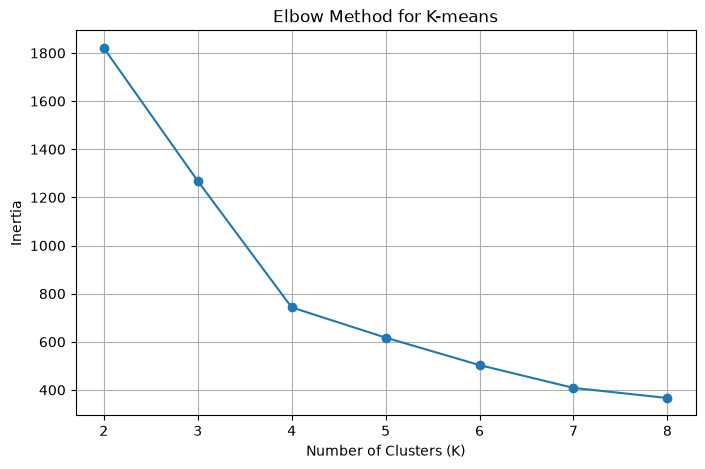

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    kmeans_results["K"],
    kmeans_results["Inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-means")
plt.xticks(range(2, 9))
plt.grid(True)

plt.show()

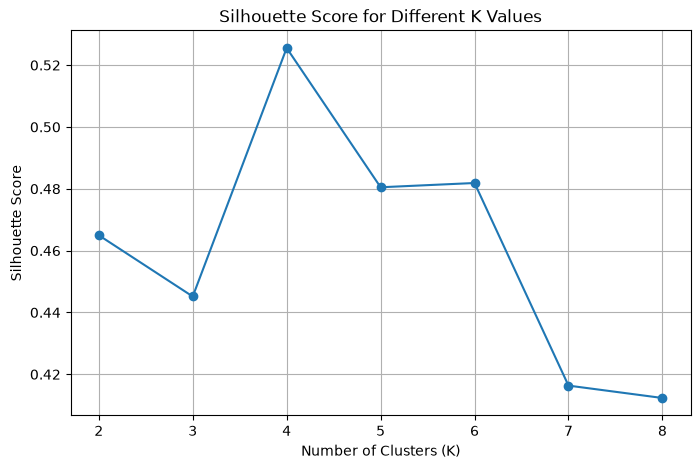

In [53]:
plt.figure(figsize=(8, 5))

plt.plot(
    kmeans_results["K"],
    kmeans_results["Silhoutte"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(range(2, 9))
plt.grid(True)

plt.show()

In [54]:
final_kmeans = KMeans(n_clusters = 4, n_init = 10, random_state = 42)
rfm["segment_id"] = final_kmeans.fit_predict(scaled_rfm)

In [55]:
segment_profile = (rfm.groupby("segment_id").agg(customer_count=("customer_id","count"),mean_recency=("recency","mean"),mean_frequency=("frequency","mean"),mean_monetary = ("monetary","mean")).round(2))
print(segment_profile)

            customer_count  mean_recency  mean_frequency  mean_monetary
segment_id                                                             
0                      436         28.86            3.77        1057.62
1                      138         24.12            6.77        7129.70
2                      419          8.77           19.40        3410.02
3                      182        109.04            2.20         685.99


In [56]:
premium_segment = segment_profile["mean_monetary"].idxmax()

print("Premium segment ID:",premium_segment)

segment_ids = list(segment_profile.index)

segment_names = {}

segment_names[premium_segment] = "Premium Customers"

remaining = [
    segment_id
    for segment_id in segment_ids
    if segment_id != premium_segment
]

loyal_segment = segment_profile.loc[
    remaining, "mean_frequency"
].idxmax()

segment_names[loyal_segment] = "Loyal Regulars"

remaining.remove(loyal_segment)

at_risk_segment = segment_profile.loc[
    remaining, "mean_recency"
].idxmax()

segment_names[at_risk_segment] = "At-Risk Customers"

remaining.remove(at_risk_segment)

for segment_id in remaining:
    segment_names[segment_id] = "Developing Customers"

rfm["segment_name"] = rfm["segment_id"].map(segment_names)

rfm["is_premium"] = (
    rfm["segment_id"] == premium_segment
)

print(rfm.head())

Premium segment ID: 1
  customer_id  recency  frequency  monetary  segment_id          segment_name  \
0       C0001       14          4    512.85           0  Developing Customers   
1       C0002       28          7   4644.90           1     Premium Customers   
2       C0003        7         22   3644.85           2        Loyal Regulars   
3       C0004        0          5    369.00           0  Developing Customers   
4       C0005      147          2    324.00           3     At-Risk Customers   

   is_premium  
0       False  
1        True  
2       False  
3       False  
4       False  


In [57]:
from sklearn.decomposition import PCA
pca = PCA(n_components = 2)

pca_data = pca.fit_transform(scaled_rfm)
print("explained variance ratio:",pca.explained_variance_ratio_)
print("Total variance ratio:",pca.explained_variance_ratio_.sum())

explained variance ratio: [0.63427875 0.21803762]
Total variance ratio: 0.8523163667502168


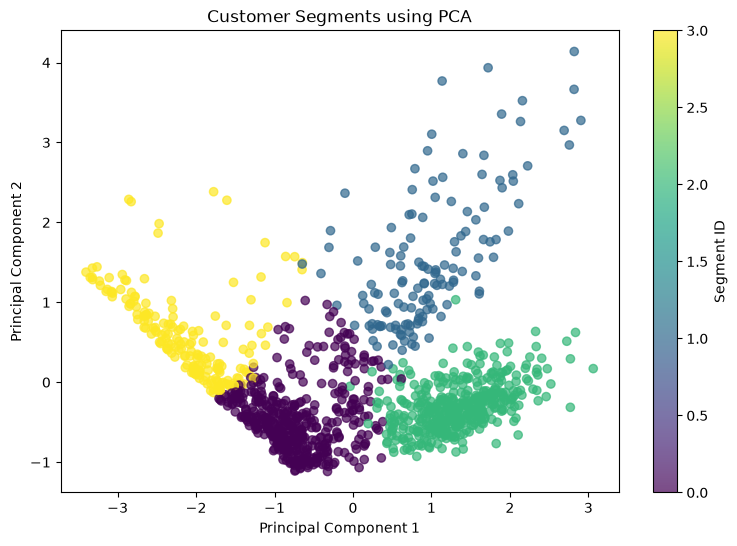

In [58]:
plt.figure(figsize=(9, 6))

plt.scatter(
    pca_data[:, 0],
    pca_data[:, 1],
    c=rfm["segment_id"],
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segments using PCA")

plt.colorbar(label="Segment ID")
plt.show()

In [59]:
from pathlib import Path
output_dir = Path('../outputs')
output_dir.mkdir(parents = True, exist_ok = True)

segment_output= rfm[["customer_id","recency","frequency","monetary","segment_id","segment_name","is_premium"]]

segment_output.to_csv(output_dir/"customer_segments.csv",index = False)

print("customer segments saved successfully")

customer segments saved successfully


In [60]:
cutoff_date = pd.Timestamp("2025-09-01 00:00:00")

orders["order_ts"] = pd.to_datetime(orders["order_ts"], errors = "coerce")

pre_cutoff_orders = orders[orders["order_ts"] < cutoff_date].copy()

pre_cutoff_completed = pre_cutoff_orders[pre_cutoff_orders["status"] == "completed"].copy()

In [61]:
cohort_customer_ids = (pre_cutoff_completed["customer_id"].unique())

print("cohort size:", len(cohort_customer_ids))

cohort size: 1156


In [62]:
september_completed = orders[
    (orders["status"] == "completed") &
    (orders["order_ts"] >= cutoff_date) &
    (orders["order_ts"] < pd.Timestamp("2025-10-01"))
]

september_customer_ids = set(
    september_completed["customer_id"].unique()
)

labels = pd.DataFrame({
    "customer_id": cohort_customer_ids
})

labels["lapsed"] = (
    ~labels["customer_id"].isin(september_customer_ids)
).astype(int)

print(labels["lapsed"].value_counts())

lapsed
0    713
1    443
Name: count, dtype: int64


In [63]:
lapsed_percentage = labels["lapsed"].mean() * 100

print("Lapsed percentage:", round(lapsed_percentage, 2), "%")

Lapsed percentage: 38.32 %


In [64]:
last_order = (pre_cutoff_completed.groupby("customer_id")["order_ts"].max())

recency = (cutoff_date - last_order).dt.days

frequency = (pre_cutoff_completed.groupby("customer_id")["order_id"].nunique())

monetary = (pre_cutoff_completed.groupby("customer_id")["order_amount"].sum())

average_discount = (pre_cutoff_completed.groupby("customer_id")["discount_pct"].mean())

final_status_orders = pre_cutoff_orders[
    pre_cutoff_orders["status"].isin(
        ["completed", "cancelled"]
    )
].copy()

cancellation_summary = (
    final_status_orders
    .assign(
        is_cancelled=lambda df: (
            df["status"] == "cancelled"
        ).astype(int)
    )
    .groupby("customer_id")
    .agg(
        cancelled_count=("is_cancelled", "sum"),
        final_order_count=("order_id", "nunique")
    )
)

cancellation_summary["cancellation_rate"] = (
    cancellation_summary["cancelled_count"] /
    cancellation_summary["final_order_count"]
)

In [65]:
print(category_orders.columns.tolist())

['order_id', 'customer_id', 'product_id', 'quantity', 'order_ts', 'status', 'discount_pct', 'order_amount', 'delivery_minutes', 'price_inr', 'category']


In [66]:
average_delivery = (
    pre_cutoff_completed
    .groupby("customer_id")["delivery_minutes"]
    .mean()
)

category_orders = pre_cutoff_completed.drop(columns = ["category"],errors = "ignore").merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left"
)

favourite_category = (
    category_orders
    .groupby("customer_id")["category"]
    .agg(
        lambda x: x.mode().iloc[0]
        if not x.mode().empty
        else "Unknown"
    )
)

In [67]:
customer_details = customers[
    [
        "customer_id",
        "city",
        "age",
        "gender",
        "signup_date"
    ]
].copy()

customer_details["signup_date"] = pd.to_datetime(
    customer_details["signup_date"],
    errors="coerce"
)

customer_details["tenure_days"] = (
    cutoff_date - customer_details["signup_date"]
).dt.days

In [68]:
features = pd.DataFrame({
    "recency": recency,
    "frequency": frequency,
    "monetary": monetary,
    "average_discount": average_discount,
    "cancellation_rate": cancellation_summary[
        "cancellation_rate"
    ],
    "average_delivery_minutes": average_delivery,
    "favourite_category": favourite_category
}).reset_index()

features = features.merge(
    customer_details[
        [
            "customer_id",
            "city",
            "age",
            "gender",
            "tenure_days"
        ]
    ],
    on="customer_id",
    how="left"
)

In [69]:
dataset = features.merge(
    labels,
    on="customer_id",
    how="inner"
)

print(dataset.head())
print(dataset.shape)

  customer_id  recency  frequency  monetary  average_discount  \
0       C0001     33.0        2.0    378.00         10.000000   
1       C0002     22.0        6.0   3946.90          6.666667   
2       C0003      1.0       20.0   3264.05         12.750000   
3       C0004     42.0        3.0    272.25         11.666667   
4       C0005    117.0        2.0    324.00         25.000000   

   cancellation_rate  average_delivery_minutes favourite_category       city  \
0           0.000000                 28.000000            Grocery    Chennai   
1           0.000000                 21.916667        Electronics      Delhi   
2           0.000000                 24.200000            Grocery  Bengaluru   
3           0.400000                 35.666667             Snacks  Bengaluru   
4           0.333333                 26.000000              Dairy  Bengaluru   

    age  gender  tenure_days  lapsed  
0  35.0    male          597       0  
1  31.0    male          562       0  
2  18.0  fe

In [70]:
numeric_features = [
    "recency",
    "frequency",
    "monetary",
    "average_discount",
    "cancellation_rate",
    "average_delivery_minutes",
    "age",
    "tenure_days"
]

categorical_features = [
    "city",
    "gender",
    "favourite_category"
]

In [71]:
from sklearn.model_selection import train_test_split

X = dataset.drop(
    columns=["customer_id", "lapsed"]
)

y = dataset["lapsed"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 924
Testing rows: 232


In [72]:
print(X_train.isnull().sum())
print(X_test.isnull().sum())

X_train = X_train.copy()
X_test = X_test.copy()

train_medians = X_train[numeric_features].median()

if train_medians.isna().any():
    raise ValueError(
        "A numerical feature contains no usable training values."
    )

X_train[numeric_features] = (
    X_train[numeric_features].fillna(train_medians)
)

X_test[numeric_features] = (
    X_test[numeric_features].fillna(train_medians)
)

X_train[categorical_features] = (
    X_train[categorical_features].fillna("Unknown")
)

X_test[categorical_features] = (
    X_test[categorical_features].fillna("Unknown")
)

assert X_train.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0

print("No missing feature values in train or test!")

recency                     0
frequency                   0
monetary                    0
average_discount            0
cancellation_rate           0
average_delivery_minutes    0
favourite_category          0
city                        0
age                         0
gender                      0
tenure_days                 0
dtype: int64
recency                     0
frequency                   0
monetary                    0
average_discount            0
cancellation_rate           0
average_delivery_minutes    0
favourite_category          0
city                        0
age                         0
gender                      0
tenure_days                 0
dtype: int64
No missing feature values in train or test!


In [73]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [74]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

baseline_predictions = np.zeros(
    len(y_test),
    dtype=int
)

print("Baseline accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("Baseline lapsed precision:",
      precision_score(
          y_test,
          baseline_predictions,
          pos_label=1,
          zero_division=0
      ))

print("Baseline lapsed recall:",
      recall_score(
          y_test,
          baseline_predictions,
          pos_label=1,
          zero_division=0
      ))

print("Baseline lapsed F1:",
      f1_score(
          y_test,
          baseline_predictions,
          pos_label=1,
          zero_division=0
      ))

Baseline accuracy: 0.6163793103448276
Baseline lapsed precision: 0.0
Baseline lapsed recall: 0.0
Baseline lapsed F1: 0.0


In [75]:
C = [0.01, 0.1, 1, 10, 100]

In [76]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(max_iter=1000)
        )
    ]
)

logistic_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

lr_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

lr_search.fit(X_train, y_train)

best_lr = lr_search.best_estimator_

print("Best Logistic Regression parameters:")
print(lr_search.best_params_)

print("Best Logistic Regression CV F1:")
print(lr_search.best_score_)

Best Logistic Regression parameters:
{'model__C': 100}
Best Logistic Regression CV F1:
0.650552962900789


In [77]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42
            )
        )
    ]
)

rf_grid = {
    "model__max_depth": [3, 5, 8],
    "model__min_samples_leaf": [5, 10, 20]
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_

print("Best Random Forest parameters:")
print(rf_search.best_params_)

print("Best Random Forest CV F1:")
print(rf_search.best_score_)

Best Random Forest parameters:
{'model__max_depth': 8, 'model__min_samples_leaf': 10}
Best Random Forest CV F1:
0.6810534884225208


In [78]:
def evaluate_model(model, X_test, y_test, model_name):

    predictions = model.predict(X_test)

    print("\n", "=" * 50)
    print(model_name)
    print("=" * 50)

    print("Confusion Matrix:")
    print(
        confusion_matrix(
            y_test,
            predictions,
            labels=[0, 1]
        )
    )

    print(
        "Precision:",
        precision_score(
            y_test,
            predictions,
            pos_label=1,
            zero_division=0
        )
    )

    print(
        "Recall:",
        recall_score(
            y_test,
            predictions,
            pos_label=1,
            zero_division=0
        )
    )

    print(
        "F1:",
        f1_score(
            y_test,
            predictions,
            pos_label=1,
            zero_division=0
        )
    )


evaluate_model(
    best_lr,
    X_test,
    y_test,
    "Logistic Regression"
)

evaluate_model(
    best_rf,
    X_test,
    y_test,
    "Random Forest"
)


Logistic Regression
Confusion Matrix:
[[111  32]
 [ 31  58]]
Precision: 0.6444444444444445
Recall: 0.651685393258427
F1: 0.6480446927374302

Random Forest
Confusion Matrix:
[[113  30]
 [ 31  58]]
Precision: 0.6590909090909091
Recall: 0.651685393258427
F1: 0.655367231638418


In [79]:
from sklearn.utils import resample
from sklearn.base import clone

train_data = X_train.copy()

train_data["lapsed"] = y_train

majority_count = train_data["lapsed"].value_counts().max()

minority_data = train_data[
    train_data["lapsed"] == 1
]

extra_minority = resample(
    minority_data,
    replace=True,
    n_samples=(
        majority_count - len(minority_data)
    ),
    random_state=42
)

balanced_train_data = pd.concat(
    [train_data, extra_minority]
)

balanced_train_data = balanced_train_data.sample(
    frac=1,
    random_state=42
)

X_train_balanced = balanced_train_data.drop(
    columns=["lapsed"]
)

y_train_balanced = balanced_train_data["lapsed"]

print(y_train_balanced.value_counts())

lapsed
1    570
0    570
Name: count, dtype: int64


In [81]:
balanced_lr = clone(best_lr)

balanced_lr.fit(
    X_train_balanced,
    y_train_balanced
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['recency','frequency','monetary',...,'age','gender','tenure_days']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all rema

In [82]:
original_lr_predictions = best_lr.predict(X_test)

balanced_lr_predictions = balanced_lr.predict(X_test)


def get_metrics(y_true, predictions):

    return {
        "Precision": precision_score(
            y_true,
            predictions,
            pos_label=1,
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            predictions,
            pos_label=1,
            zero_division=0
        ),

        "F1": f1_score(
            y_true,
            predictions,
            pos_label=1,
            zero_division=0
        )
    }


comparison = pd.DataFrame({
    "Original Logistic Regression": get_metrics(
        y_test,
        original_lr_predictions
    ),

    "Balanced Logistic Regression": get_metrics(
        y_test,
        balanced_lr_predictions
    )
}).T

print(comparison.round(3))

                              Precision  Recall     F1
Original Logistic Regression      0.644   0.652  0.648
Balanced Logistic Regression      0.589   0.854  0.697


In [84]:
rf_preprocessor = best_rf.named_steps["preprocessor"]

rf_model = best_rf.named_steps["model"]

rf_feature_names = (
    rf_preprocessor.get_feature_names_out()
)

rf_importance = pd.DataFrame({
    "feature": rf_feature_names,
    "importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    "importance",
    ascending=False
)

print(rf_importance.head(5))

                         feature  importance
1                 num__frequency    0.279589
2                  num__monetary    0.271176
0                   num__recency    0.115149
5  num__average_delivery_minutes    0.061286
4         num__cancellation_rate    0.052325


In [85]:
lr_preprocessor = best_lr.named_steps["preprocessor"]

lr_model = best_lr.named_steps["model"]

lr_feature_names = (
    lr_preprocessor.get_feature_names_out()
)

lr_coefficients = pd.DataFrame({
    "feature": lr_feature_names,
    "coefficient": lr_model.coef_[0]
})

lr_coefficients["absolute_coefficient"] = (
    lr_coefficients["coefficient"].abs()
)

lr_coefficients = lr_coefficients.sort_values(
    "absolute_coefficient",
    ascending=False
)

print(lr_coefficients.head(3))

                                feature  coefficient  absolute_coefficient
1                        num__frequency    -1.698239              1.698239
15  cat__favourite_category_Electronics    -1.136713              1.136713
16      cat__favourite_category_Grocery    -0.448673              0.448673


In [86]:
import joblib

# Choose the model using cross-validation F1, not test F1
if rf_search.best_score_ >= lr_search.best_score_:
    selected_model = best_rf
    selected_model_name = "Random Forest"
else:
    selected_model = best_lr
    selected_model_name = "Logistic Regression"

print("Selected model:", selected_model_name)

joblib.dump(
    selected_model,
    "../outputs/lapse_model.joblib"
)



Selected model: Random Forest


['../outputs/lapse_model.joblib']

In [87]:
loaded_model = joblib.load(
    "../outputs/lapse_model.joblib"
)

original_predictions = selected_model.predict(X_test)

reloaded_predictions = loaded_model.predict(X_test)

print(
    "Predictions identical:",
    np.array_equal(
        original_predictions,
        reloaded_predictions
    )
)

assert np.array_equal(
    original_predictions,
    reloaded_predictions
)

Predictions identical: True


In [88]:
test_probabilities = selected_model.predict_proba(
    X_test
)[:, 1]

In [101]:
# retention_results = pd.DataFrame({
#     "customer_id": X_test.index,
#     "lapse_probability": test_probabilities,
#     "actually_lapsed": y_test.values
# })

retention_results = pd.DataFrame({
    "customer_id": dataset.loc[X_test.index, "customer_id"].values,
    "lapse_probability": test_probabilities,
    "actually_lapsed": y_test.values
})

In [102]:
segments_df = pd.read_csv(
    "../outputs/customer_segments.csv"
)

retention_results["customer_id"] = (
    retention_results["customer_id"].astype(str)
)

segments_df["customer_id"] = (
    segments_df["customer_id"].astype(str)
)

retention_results = retention_results.drop(
    columns=["is_premium"],
    errors="ignore"
)

retention_results = retention_results.merge(
    segments_df[["customer_id", "is_premium"]],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

In [103]:
print(retention_results["is_premium"].value_counts(dropna=False))

is_premium
False    192
True      40
Name: count, dtype: int64


In [106]:
premium_customers = retention_results[
    retention_results["is_premium"] == True
].copy()

retention_list = (
    premium_customers
    .sort_values(
        "lapse_probability",
        ascending=False
    )
    .head(10)
)

retention_list = retention_list[
    [
        "customer_id",
        "lapse_probability",
        "actually_lapsed"
    ]
]

retention_list.to_csv(
    "../outputs/retention_list.csv",
    index=False
)

print(retention_list)

    customer_id  lapse_probability  actually_lapsed
13        C0862           0.491035                0
27        C1112           0.484067                0
227       C0060           0.479796                0
5         C0802           0.479642                0
165       C1008           0.477817                0
121       C1000           0.462420                0
58        C0525           0.459718                1
82        C0133           0.456237                0
190       C0267           0.452514                0
16        C0167           0.452159                0


In [107]:
actual_lapsed_count = (
    retention_list["actually_lapsed"].sum()
)

print(
    "Number of selected Premium customers who actually lapsed:",
    actual_lapsed_count
)

Number of selected Premium customers who actually lapsed: 1
